# Projet 9 — Mission 1 : Analysez le catalogue
## Étape 1 — Audit qualité et nettoyage des données

**Contexte.** MeloWave, distributeur musical indépendant, prépare son comité éditorial mensuel. Camille Roussel (Directrice des études musicales) demande un état des lieux chiffré de la base de morceaux avant toute analyse.

**Objectif de cette étape.**
1. Charger le jeu de données et en décrire la dimension, les types et la signification de chaque variable.
2. Établir un état des lieux des valeurs manquantes et des doublons (doublons stricts *vs* `track_id` dupliqués).
3. Produire un jeu de données nettoyé, **chaque décision étant documentée et justifiée** (suppression, conservation, transformation).

**Principe directeur.** Aucune ligne n'est supprimée sans justification écrite. Le nombre de lignes est tracé avant et après chaque opération, et le journal des décisions est récapitulé en fin de notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

CHEMIN = "spotify-tracks-dataset-detailed.csv"

---
## 1. Chargement et dimension du jeu de données

In [2]:
df_brut = pd.read_csv(CHEMIN)

# On travaille sur une copie : df_brut reste la référence intacte pour comparer avant / après.
df = df_brut.copy()

print(f"Dimension : {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"Taille en mémoire : {df.memory_usage(deep=True).sum() / 1024**2:.1f} Mo")

Dimension : 114,000 lignes x 20 colonnes
Taille en mémoire : 48.8 Mo


In [3]:
df.head(3)

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,-6.7460,0,0.1430,0.0322,0.0000,0.3580,0.7150,87.9170,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,-17.2350,1,0.0763,0.9240,0.0000,0.1010,0.2670,77.4890,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,-9.7340,1,0.0557,0.2100,0.0000,0.1170,0.1200,76.3320,4,acoustic


### 1.1 Dictionnaire des variables

Le fichier contient 20 colonnes. On les classe par rôle analytique, ce qui conditionne les traitements applicables (une moyenne n'a pas de sens sur `key`, codée numériquement mais qualitative).

| Colonne | Type | Rôle | Signification | Étendue attendue |
|---|---|---|---|---|
| `track_id` | texte | Identifiant | Identifiant Spotify du morceau | — |
| `artists` | texte | Dimension | Artiste(s), séparés par `;` en cas de featuring | — |
| `album_name` | texte | Dimension | Album d'où provient le morceau | — |
| `track_name` | texte | Dimension | Titre du morceau | — |
| `popularity` | entier | **Métrique** | Score Spotify basé sur le nombre d'écoutes récentes | 0 à 100 |
| `duration_ms` | entier | **Métrique** | Durée du morceau en millisecondes | > 0 |
| `explicit` | booléen | Dimension | Présence de paroles explicites | True / False |
| `danceability` | décimal | **Métrique** | Aptitude à la danse (tempo, stabilité rythmique, force du beat) | 0 à 1 |
| `energy` | décimal | **Métrique** | Intensité et activité perçues | 0 à 1 |
| `key` | entier | **Dimension** (codée) | Tonalité, notation *pitch class* (0 = Do, 1 = Do#, … 11 = Si) | 0 à 11, -1 si inconnue |
| `loudness` | décimal | **Métrique** | Volume moyen en décibels | ~ -60 à 0 dB |
| `mode` | entier | **Dimension** (codée) | Modalité : 1 = majeur, 0 = mineur | 0 / 1 |
| `speechiness` | décimal | **Métrique** | Présence de paroles parlées | 0 à 1 |
| `acousticness` | décimal | **Métrique** | Confiance dans le caractère acoustique | 0 à 1 |
| `instrumentalness` | décimal | **Métrique** | Probabilité d'absence de voix | 0 à 1 |
| `liveness` | décimal | **Métrique** | Probabilité d'un enregistrement live | 0 à 1 |
| `valence` | décimal | **Métrique** | Positivité musicale (1 = joyeux, 0 = triste/en colère) | 0 à 1 |
| `tempo` | décimal | **Métrique** | Tempo estimé en BPM | > 0 |
| `time_signature` | entier | **Dimension** (codée) | Métrique de la mesure (nombre de temps par mesure) | 3 à 7 |
| `track_genre` | texte | Dimension | Genre auquel le morceau est rattaché | 114 modalités |

> **Point de vigilance.** `key`, `mode` et `time_signature` sont stockées en entier mais sont **qualitatives**. Elles seront exclues des statistiques descriptives numériques et des matrices de corrélation de l'étape 2.

In [4]:
# Types réels détectés par pandas, et classification retenue pour la suite
ID_COLS         = ["track_id"]
TEXTE_COLS      = ["artists", "album_name", "track_name"]
CAT_COLS        = ["track_genre", "explicit", "key", "mode", "time_signature"]
AUDIO_FEATURES  = ["danceability", "energy", "loudness", "speechiness",
                   "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
NUM_COLS        = AUDIO_FEATURES + ["popularity", "duration_ms"]

recap_types = pd.DataFrame({
    "type_pandas": df.dtypes.astype(str),
    "n_uniques": df.nunique(),
    "role": ["identifiant" if c in ID_COLS
             else "texte" if c in TEXTE_COLS
             else "qualitative" if c in CAT_COLS
             else "quantitative" for c in df.columns],
})
recap_types

,type_pandas,n_uniques,role
track_id,object,89741,identifiant
artists,object,31437,texte
album_name,object,46589,texte
track_name,object,73608,texte
popularity,int64,101,quantitative
duration_ms,int64,50697,quantitative
explicit,bool,2,qualitative
danceability,float64,1174,quantitative
energy,float64,2083,quantitative
key,int64,12,qualitative


---
## 2. État des lieux des valeurs manquantes

In [5]:
na = df.isna().sum()
na_recap = pd.DataFrame({"n_manquants": na, "taux_%": (na / len(df) * 100).round(4)})
print("Total de valeurs manquantes dans le fichier :", int(na.sum()))
na_recap[na_recap.n_manquants > 0]

Total de valeurs manquantes dans le fichier : 3


,n_manquants,taux_%
artists,1,0.0009
album_name,1,0.0009
track_name,1,0.0009


In [6]:
# Isolement de la ou des lignes concernées
lignes_na = df[df.isna().any(axis=1)]
print(f"{len(lignes_na)} ligne(s) concernée(s)")
lignes_na

1 ligne(s) concernée(s)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.5010,0.5830,7,-9.4600,0,0.0605,0.6900,0.0040,0.0747,0.7340,138.3910,4,k-pop


**Constat.** Une seule ligne sur 114 000 (0,0009 %) porte des valeurs manquantes, et elle les cumule sur les trois colonnes d'identification textuelle (`artists`, `album_name`, `track_name`). Cette même ligne présente par ailleurs une durée nulle (voir §4).

**→ Décision D1 : suppression de cette ligne.** Elle est inexploitable pour les classements d'artistes de l'étape 2 et son impact statistique est négligeable. Toute imputation serait arbitraire (on ne peut pas inventer un nom d'artiste).

Aucune autre colonne ne présente de valeur manquante : les 16 features audio et `popularity` sont complètes à 100 %.

---
## 3. État des lieux des doublons

Le brief impose de distinguer deux notions très différentes, qui n'appellent pas le même traitement.

### 3.1 Doublons stricts — lignes identiques sur **toutes** les colonnes

In [7]:
n_stricts = df.duplicated(keep=False).sum()
n_a_supprimer = df.duplicated().sum()
print(f"Lignes impliquées dans un doublon strict : {n_stricts:,}")
print(f"Lignes excédentaires à supprimer          : {n_a_supprimer:,} ({n_a_supprimer/len(df)*100:.2f} %)")

# Exemple : un morceau apparaissant deux fois à l'identique
exemple = df[df.duplicated(keep=False)].sort_values("track_id").head(2)
exemple[["track_id", "artists", "track_name", "popularity", "track_genre"]]

Lignes impliquées dans un doublon strict : 894
Lignes excédentaires à supprimer          : 450 (0.39 %)


,track_id,artists,track_name,popularity,track_genre
52766,00JZ83w0Qm09f4PwWj06sM,George Jones,A Good Year For The Roses,12,honky-tonk
52714,00JZ83w0Qm09f4PwWj06sM,George Jones,A Good Year For The Roses,12,honky-tonk


**Constat.** 450 lignes sont des copies exactes d'une autre ligne, genre compris. Il s'agit d'une erreur d'ingestion : la même information est comptée deux fois.

**→ Décision D2 : suppression des 450 lignes excédentaires** (`drop_duplicates()`, conservation de la première occurrence). Aucune information n'est perdue puisque les lignes sont identiques colonne par colonne.

### 3.2 `track_id` dupliqués — un même morceau rattaché à plusieurs genres

In [8]:
dup_id = df[df.duplicated("track_id", keep=False)]
n_genres_par_track = dup_id.groupby("track_id")["track_genre"].nunique()

print(f"track_id distincts dans le fichier        : {df['track_id'].nunique():,} / {len(df):,} lignes")
print(f"track_id apparaissant plusieurs fois      : {dup_id['track_id'].nunique():,}")
print(f"  - dont rattachés a plusieurs genres     : {(n_genres_par_track > 1).sum():,}")
print(f"  - dont repetes au sein d'un meme genre  : {(n_genres_par_track == 1).sum():,}")
print(f"Nombre maximal de genres pour un morceau  : {n_genres_par_track.max()}")

track_id distincts dans le fichier        : 89,741 / 114,000 lignes
track_id apparaissant plusieurs fois      : 16,641
  - dont rattachés a plusieurs genres     : 16,299
  - dont repetes au sein d'un meme genre  : 342
Nombre maximal de genres pour un morceau  : 9


In [9]:
# Illustration : le morceau rattache au plus grand nombre de genres
id_champion = n_genres_par_track.idxmax()
df[df.track_id == id_champion][["track_id", "artists", "track_name", "popularity", "energy", "track_genre"]]

,track_id,artists,track_name,popularity,energy,track_genre
8315,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,blues
19759,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,country
34728,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,folk
62226,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,j-pop
63087,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,j-rock
82064,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,power-pop
84129,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,psych-rock
99727,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,singer-songwriter
102732,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,songwriter


**Constat.** La quasi-totalité des `track_id` dupliqués (16 299 sur 16 641) correspondent à des morceaux **rattachés à plusieurs genres** — jusqu'à 9 genres pour un même titre. Ce n'est pas un défaut de qualité : c'est la **granularité du jeu de données**, dont la maille est le couple *(morceau, genre)* et non le morceau.

Vérifions que les 342 `track_id` répétés au sein d'un même genre correspondent bien aux doublons stricts identifiés au §3.1, et non à un problème distinct.

In [10]:
apres_stricts = df.drop_duplicates()
dup_id2 = apres_stricts[apres_stricts.duplicated("track_id", keep=False)]
reste_mono = dup_id2.groupby("track_id")["track_genre"].nunique().eq(1).sum()
print(f"track_id repetes dans un meme genre APRES suppression des doublons stricts : {reste_mono}")

track_id repetes dans un meme genre APRES suppression des doublons stricts : 0


In [11]:
# Les features audio sont-elles identiques d'une occurrence a l'autre du meme morceau ?
variabilite = dup_id.groupby("track_id")[NUM_COLS].nunique().max()
print("Nombre maximal de valeurs distinctes par track_id duplique :")
print(variabilite)

Nombre maximal de valeurs distinctes par track_id duplique :
danceability        1
energy              1
loudness            1
speechiness         1
acousticness        1
instrumentalness    1
liveness            1
valence             1
tempo               1
popularity          2
duration_ms         1
dtype: int64


**Constat déterminant.** Toutes les features audio (`danceability`, `energy`, `loudness`, `tempo`…) et `duration_ms` sont **strictement identiques** d'une occurrence à l'autre d'un même `track_id`. Seule `popularity` peut prendre 2 valeurs distinctes, ce qui traduit un score relevé à deux instants différents lors de la constitution du fichier.

**→ Décision D3 : conservation des `track_id` multi-genres, et construction de deux vues distinctes.**

| Vue | Maille | Usage |
|---|---|---|
| `df_genres` | (morceau, genre) | Toute analyse **par genre** : popularité selon le genre, profil audio comparé, contenu explicite par genre (étapes 2 et 3) |
| `df_tracks` | morceau unique | Toute analyse **du catalogue** : distributions des variables audio, classements d'artistes, détection d'outliers |

**Justification.** Supprimer les multi-genres appauvrirait l'analyse par genre : un morceau pop-rock disparaîtrait de l'un des deux genres, faussant leur comparaison. À l'inverse, garder les doublons pour les distributions globales **surpondérerait** mécaniquement les morceaux transversaux, qui pèseraient jusqu'à 9 fois plus lourd qu'un titre mono-genre. Une seule table ne peut pas servir les deux usages : d'où les deux vues.

Pour `df_tracks`, la popularité retenue est la valeur **maximale** observée pour le morceau (score le plus récent / le plus favorable), afin d'éviter de dépendre de l'ordre des lignes.

---
## 4. Valeurs impossibles et valeurs à interpréter

Au-delà des NA et des doublons, un audit doit repérer les valeurs présentes mais invalides au regard de la définition métier de la variable.

In [12]:
controles = {
    "duration_ms = 0 (duree nulle)":            (df.duration_ms == 0).sum(),
    "tempo = 0 BPM (tempo non detecte)":        (df.tempo == 0).sum(),
    "time_signature = 0 (metrique invalide)":   (df.time_signature == 0).sum(),
    "key = -1 (tonalite inconnue)":             (df.key == -1).sum(),
    "popularity = 0 (aucune ecoute recente)":   (df.popularity == 0).sum(),
    "loudness > 0 dB":                          (df.loudness > 0).sum(),
    "features audio hors [0, 1]":               sum(((df[c] < 0) | (df[c] > 1)).sum()
                                                    for c in ["danceability", "energy", "speechiness",
                                                              "acousticness", "instrumentalness",
                                                              "liveness", "valence"]),
}
recap_ctrl = pd.DataFrame.from_dict(controles, orient="index", columns=["n_lignes"])
recap_ctrl["taux_%"] = (recap_ctrl.n_lignes / len(df) * 100).round(2)
recap_ctrl

,n_lignes,taux_%
duration_ms = 0 (duree nulle),1,0.0000
tempo = 0 BPM (tempo non detecte),157,0.1400
time_signature = 0 (metrique invalide),163,0.1400
key = -1 (tonalite inconnue),0,0.0000
popularity = 0 (aucune ecoute recente),16020,14.0500
loudness > 0 dB,90,0.0800
"features audio hors [0, 1]",0,0.0000


**Lecture des contrôles.**

- **`duration_ms = 0` (1 ligne)** — durée physiquement impossible. Il s'agit de la même ligne que celle du §2. **→ Décision D4 : suppression** (déjà couverte par D1).
- **`tempo = 0` (157 lignes, 0,14 %)** — un morceau ne peut pas avoir un tempo nul ; l'algorithme d'estimation de Spotify a échoué. Ce n'est pas une vraie valeur mais un code d'échec. **→ Décision D5 : remplacement par `NaN`, sans supprimer la ligne.** Supprimer la ligne détruirait 18 autres variables valides ; laisser 0 tirerait artificiellement vers le bas la moyenne du tempo et fabriquerait une corrélation fictive.
- **`time_signature = 0` (163 lignes)** — une mesure comporte au minimum 1 temps. Même raisonnement. **→ Décision D6 : remplacement par `NaN`.**
- **`key = -1`** — code documenté pour « tonalité inconnue ». Absent de ce fichier, aucun traitement nécessaire.
- **`loudness > 0 dB`** — techniquement possible sur des masterings récents très compressés ; valeurs plausibles, **conservées**.
- **`popularity = 0` (16 020 lignes, 14,1 %)** — cas le plus délicat. Le score est calculé sur les écoutes récentes : 0 signifie « aucune écoute récente », pas « donnée manquante ». La valeur est donc **légitime**. **→ Décision D7 : conservation, avec création d'un indicateur `popularity_zero`.**

> **Point de vigilance pour toute la suite du projet.** Ces 14 % de zéros créent un pic à l'origine qui tire les moyennes vers le bas et accentue l'asymétrie de la distribution de `popularity`. Toute moyenne de popularité devra être lue en gardant cette masse en tête, et systématiquement doublée d'une médiane. Elle sera explicitement commentée à l'étape 2.

In [13]:
# Durees extremes : outliers reels ou erreurs ?
print("Duree minimale non nulle :", df[df.duration_ms > 0].duration_ms.min() / 1000, "s")
df.nlargest(3, "duration_ms")[["track_name", "artists", "duration_ms", "track_genre"]] \
  .assign(duree_min=lambda d: (d.duration_ms / 60000).round(1))

Duree minimale non nulle : 8.586 s


,track_name,artists,duration_ms,track_genre,duree_min
73617,Unity (Voyage Mix) Pt. 1,Tale Of Us,5237295,minimal-techno,87.3000
10935,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,4789026,breakbeat,79.8000
10984,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,4789026,breakbeat,79.8000


**Constat.** Les durées extrêmes (jusqu'à 87 minutes) correspondent à des *DJ mixes* et *continuous mixes* de genres électroniques — des formats longs authentiques, pas des erreurs de saisie.

**→ Décision D8 : conservation des durées extrêmes.** Elles seront traitées comme des valeurs aberrantes *statistiques* à l'étape 2 (méthode IQR) mais restent des observations *métier* valides : les écarter fausserait le profil des genres électroniques.

---
## 5. Contrôle de la structure du catalogue

Avant de nettoyer, on vérifie la façon dont le fichier a été constitué : cela conditionne l'interprétation de toutes les analyses par genre.

In [14]:
tailles = df.groupby("track_genre").size()
print(f"Nombre de genres           : {df.track_genre.nunique()}")
print(f"Lignes par genre — min     : {tailles.min():,}")
print(f"Lignes par genre — max     : {tailles.max():,}")
print(f"Lignes par genre — ecart-type : {tailles.std():.2f}")

Nombre de genres           : 114
Lignes par genre — min     : 1,000
Lignes par genre — max     : 1,000
Lignes par genre — ecart-type : 0.00


**Constat majeur.** Le fichier contient exactement **1 000 lignes pour chacun des 114 genres** (écart-type nul). Le jeu de données est **équilibré par construction** : il s'agit d'un échantillon stratifié, pas d'un extrait représentatif du catalogue réel de MeloWave.

**Conséquence pour le comité éditorial.** On ne pourra jamais conclure qu'un genre est « plus présent » qu'un autre dans le catalogue — cette information a été détruite par l'échantillonnage. En revanche, la comparaison des genres entre eux (popularité moyenne, profil audio, taux d'explicite) est parfaitement légitime, et même facilitée : les effectifs égaux garantissent une puissance statistique homogène pour les tests de l'étape 3.

---
## 6. Nettoyage — application et traçabilité des décisions

Chaque opération est appliquée séquentiellement, avec le décompte des lignes avant et après.

In [15]:
journal = []

def tracer(etape, df_avant, df_apres):
    """Enregistre l'effet d'une operation de nettoyage sur le nombre de lignes."""
    journal.append({
        "etape": etape,
        "lignes_avant": len(df_avant),
        "lignes_apres": len(df_apres),
        "delta": len(df_apres) - len(df_avant),
    })
    print(f"{etape:<45} {len(df_avant):>7,} -> {len(df_apres):>7,}  ({len(df_apres)-len(df_avant):+,})")

df = df_brut.copy()
print(f"{'JEU DE DONNEES BRUT':<45} {len(df):>7,}")

JEU DE DONNEES BRUT                           114,000


In [16]:
# --- D2 : suppression des doublons stricts -----------------------------------
avant = df
df = df.drop_duplicates(keep="first")
tracer("D2 - Suppression des doublons stricts", avant, df)

# --- D1 / D4 : suppression de la ligne incomplete et de duree nulle ----------
avant = df
df = df[df[["artists", "album_name", "track_name"]].notna().all(axis=1)]
tracer("D1 - Suppression des lignes incompletes", avant, df)

avant = df
df = df[df.duration_ms > 0]
tracer("D4 - Suppression des durees nulles", avant, df)

df = df.reset_index(drop=True)

D2 - Suppression des doublons stricts         114,000 -> 113,550  (-450)
D1 - Suppression des lignes incompletes       113,550 -> 113,549  (-1)
D4 - Suppression des durees nulles            113,549 -> 113,549  (+0)


In [17]:
# --- D5 / D6 : neutralisation des codes d'echec (remplacement par NaN) ------
n_tempo = (df.tempo == 0).sum()
n_ts    = (df.time_signature == 0).sum()

df.loc[df.tempo == 0, "tempo"] = np.nan
df.loc[df.time_signature == 0, "time_signature"] = np.nan

print(f"D5 - tempo = 0 remplaces par NaN           : {n_tempo:>5,} valeurs")
print(f"D6 - time_signature = 0 remplaces par NaN  : {n_ts:>5,} valeurs")
print("     (aucune ligne supprimee : les autres variables de ces lignes restent exploitables)")

D5 - tempo = 0 remplaces par NaN           :   157 valeurs
D6 - time_signature = 0 remplaces par NaN  :   163 valeurs
     (aucune ligne supprimee : les autres variables de ces lignes restent exploitables)


### 6.1 Transformations et variables dérivées

Trois transformations préparent les étapes suivantes, sans modifier l'information d'origine.

In [18]:
# T1 - Duree en secondes et en minutes : lisibilite des graphiques (recommandation du brief)
df["duration_s"]   = df["duration_ms"] / 1000
df["duration_min"] = df["duration_ms"] / 60000

# T2 - Indicateur de popularite nulle : permet d'isoler la masse a 0 dans les analyses
df["popularity_zero"] = df["popularity"].eq(0)

# T3 - Nombre de genres et nombre d'artistes par morceau
#      n_artistes prepare l'eclatement des featurings demande a l'etape 2
df["n_genres"]   = df.groupby("track_id")["track_genre"].transform("nunique")
df["n_artistes"] = df["artists"].str.split(";").str.len()

# Typage explicite des variables qualitatives codees en entier
for col in ["key", "mode"]:
    df[col] = df[col].astype("category")
df["track_genre"] = df["track_genre"].astype("category")

print("Variables derivees creees :", ["duration_s", "duration_min", "popularity_zero", "n_genres", "n_artistes"])
print(f"Morceaux avec featuring (separateur ';') : {(df.n_artistes > 1).sum():,} lignes "
      f"({(df.n_artistes > 1).mean()*100:.1f} %)")

Variables derivees creees : ['duration_s', 'duration_min', 'popularity_zero', 'n_genres', 'n_artistes']
Morceaux avec featuring (separateur ';') : 29,893 lignes (26.3 %)


### 6.2 Construction des deux vues d'analyse (décision D3)

In [19]:
# Vue 1 - maille (morceau, genre) : analyses PAR GENRE
df_genres = df.copy()

# Vue 2 - maille morceau unique : analyses DU CATALOGUE
#         popularity = valeur maximale observee, pour ne pas dependre de l'ordre des lignes
pop_max = df.groupby("track_id")["popularity"].transform("max")
df_tracks = (df.assign(popularity=pop_max)
               .sort_values(["track_id", "track_genre"])
               .drop_duplicates(subset="track_id", keep="first")
               .drop(columns="track_genre")
               .reset_index(drop=True))

print(f"df_genres  (morceau x genre) : {len(df_genres):>7,} lignes")
print(f"df_tracks  (morceau unique)  : {len(df_tracks):>7,} lignes")
print(f"Ecart = morceaux multi-genres comptes plusieurs fois : {len(df_genres) - len(df_tracks):,}")

df_genres  (morceau x genre) : 113,549 lignes
df_tracks  (morceau unique)  :  89,740 lignes
Ecart = morceaux multi-genres comptes plusieurs fois : 23,809


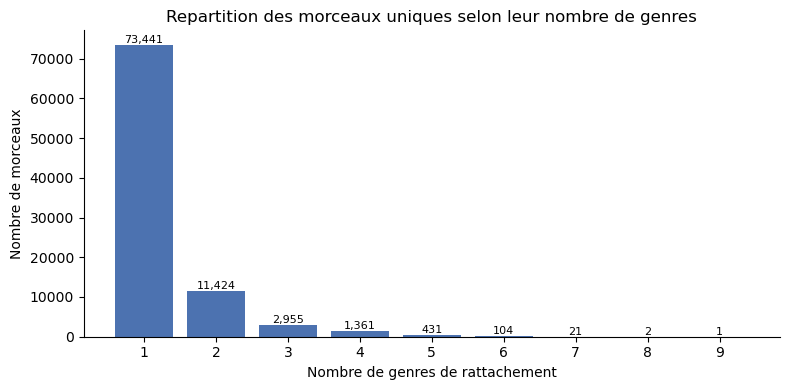

Part des morceaux rattaches a plus d'un genre : 18.2 %


In [20]:
# Repartition des morceaux selon leur nombre de genres de rattachement
repartition = df_tracks.n_genres.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(repartition.index.astype(str), repartition.values, color="#4C72B0")
ax.set_xlabel("Nombre de genres de rattachement")
ax.set_ylabel("Nombre de morceaux")
ax.set_title("Repartition des morceaux uniques selon leur nombre de genres")
for x, v in zip(repartition.index.astype(str), repartition.values):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

part_multi = (df_tracks.n_genres > 1).mean() * 100
print(f"Part des morceaux rattaches a plus d'un genre : {part_multi:.1f} %")

**Lecture du graphique.** 82 % des morceaux uniques appartiennent à un seul genre ; les 18 % restants sont transversaux, avec une décroissance rapide au-delà de 2 genres. C'est précisément cette minorité qui justifie la double vue : sans déduplication, ces 18 % pèseraient jusqu'à 9 fois leur poids réel dans les distributions globales du catalogue.

---
## 7. Contrôle final du jeu de données nettoyé

In [21]:
controles_finaux = {
    "Doublons stricts residuels (df_genres)":       df_genres.duplicated().sum(),
    "track_id dupliques (df_tracks)":               df_tracks.track_id.duplicated().sum(),
    "Valeurs manquantes sur artists/track_name":    df_genres[["artists", "track_name", "album_name"]].isna().sum().sum(),
    "Durees nulles ou negatives":                   (df_genres.duration_ms <= 0).sum(),
    "Tempos a 0 (doivent valoir NaN)":              (df_genres.tempo == 0).sum(),
    "Genres presents":                              df_genres.track_genre.nunique(),
}
for k, v in controles_finaux.items():
    print(f"{k:<48} : {v:,}")

print("\nValeurs manquantes introduites volontairement (codes d'echec neutralises) :")
print(df_genres[["tempo", "time_signature"]].isna().sum())

Doublons stricts residuels (df_genres)           : 0
track_id dupliques (df_tracks)                   : 0
Valeurs manquantes sur artists/track_name        : 0
Durees nulles ou negatives                       : 0
Tempos a 0 (doivent valoir NaN)                  : 0
Genres presents                                  : 114

Valeurs manquantes introduites volontairement (codes d'echec neutralises) :
tempo             157
time_signature    163
dtype: int64


In [22]:
# Journal complet des suppressions de lignes
journal_df = pd.DataFrame(journal)
journal_df["taux_perte_%"] = (journal_df.delta.abs() / len(df_brut) * 100).round(3)
journal_df

,etape,lignes_avant,lignes_apres,delta,taux_perte_%
0,D2 - Suppression des doublons stricts,114000,113550,-450,0.3950
1,D1 - Suppression des lignes incompletes,113550,113549,-1,0.0010
2,D4 - Suppression des durees nulles,113549,113549,0,0.0000


In [23]:
perte = len(df_brut) - len(df_genres)
print(f"Lignes brutes    : {len(df_brut):,}")
print(f"Lignes nettoyees : {len(df_genres):,}")
print(f"Perte totale     : {perte:,} lignes ({perte/len(df_brut)*100:.2f} %)")

Lignes brutes    : 114,000
Lignes nettoyees : 113,549
Perte totale     : 451 lignes (0.40 %)


---
## 8. Synthèse — journal des décisions

| # | Constat | Volume | Décision | Justification |
|---|---|---|---|---|
| **D1** | 1 ligne sans `artists`, `album_name` ni `track_name` | 1 ligne | **Supprimer** | Inexploitable pour les classements d'artistes ; toute imputation serait arbitraire ; impact nul (0,001 %) |
| **D2** | Lignes strictement identiques sur les 20 colonnes | 450 lignes | **Supprimer** | Erreur d'ingestion : la même information comptée deux fois ; aucune perte d'information |
| **D3** | `track_id` rattachés à plusieurs genres (jusqu'à 9) | 16 299 morceaux | **Conserver**, et créer deux vues (`df_genres` / `df_tracks`) | Caractéristique de la maille *(morceau, genre)*, pas un défaut. Supprimer appauvrirait l'analyse par genre ; conserver sans dédupliquer surpondérerait les morceaux transversaux dans les distributions globales |
| **D4** | `duration_ms = 0` | 1 ligne (la même que D1) | **Supprimer** | Durée physiquement impossible |
| **D5** | `tempo = 0` BPM | 157 valeurs | **Remplacer par `NaN`** | Code d'échec de détection, pas une mesure. Supprimer la ligne détruirait 18 variables valides ; garder 0 fausserait moyennes et corrélations |
| **D6** | `time_signature = 0` | 163 valeurs | **Remplacer par `NaN`** | Métrique de mesure invalide (minimum 1 temps) ; même raisonnement que D5 |
| **D7** | `popularity = 0` | 16 020 lignes (14,1 %) | **Conserver** + indicateur `popularity_zero` | Valeur légitime (« aucune écoute récente »), pas une donnée manquante. À signaler systématiquement dans l'interprétation |
| **D8** | Durées extrêmes (jusqu'à 87 min) | quelques dizaines | **Conserver** | *DJ mixes* et formats longs authentiques ; les écarter fausserait le profil des genres électroniques. Traités comme outliers statistiques à l'étape 2 |
| **T1** | Durée en millisecondes | — | **Ajouter** `duration_s`, `duration_min` | Lisibilité des graphiques (recommandation du brief) |
| **T2** | Masse de popularité à 0 | — | **Ajouter** `popularity_zero` | Permet d'isoler ou d'exclure ces morceaux dans les analyses de popularité |
| **T3** | Featurings (`;`) et multi-genres | — | **Ajouter** `n_artistes`, `n_genres` | Prépare l'éclatement des artistes et le contrôle de la duplication à l'étape 2 |

### Bilan chiffré

- **114 000 lignes brutes → 113 549 lignes nettoyées** (perte de 451 lignes, soit **0,40 %**).
- **89 741 morceaux uniques** dans la vue catalogue `df_tracks`.
- **114 genres**, exactement 1 000 lignes chacun avant nettoyage : échantillon **stratifié équilibré**.
- Seules valeurs manquantes du jeu nettoyé : 157 `tempo` et 163 `time_signature`, **introduites volontairement** en neutralisation de codes d'échec.

### Trois points à retenir pour les étapes suivantes

1. **Utiliser `df_genres` pour les analyses par genre, `df_tracks` pour les distributions et classements du catalogue.** Confondre les deux vues fausse mécaniquement les résultats.
2. **Les 14 % de popularité à 0** créent un pic à l'origine : toute moyenne de popularité doit être accompagnée d'une médiane et commentée à cet égard.
3. **L'équilibre 1 000 morceaux par genre est artificiel.** Aucune conclusion sur la « présence » relative d'un genre dans le catalogue n'est possible ; seules les comparaisons entre genres sont valides.

---
## 9. Export du jeu de données nettoyé

In [24]:
df_genres.to_csv("spotify_clean_genres.csv", index=False)
df_tracks.to_csv("spotify_clean_tracks.csv", index=False)

print(f"spotify_clean_genres.csv  -> {len(df_genres):,} lignes x {df_genres.shape[1]} colonnes (maille morceau x genre)")
print(f"spotify_clean_tracks.csv  -> {len(df_tracks):,} lignes x {df_tracks.shape[1]} colonnes (maille morceau unique)")

spotify_clean_genres.csv  -> 113,549 lignes x 25 colonnes (maille morceau x genre)
spotify_clean_tracks.csv  -> 89,740 lignes x 24 colonnes (maille morceau unique)
